# GVH Diagonal Cubic — A1 Conditional Composition and Coefficient Identifiability Gate — FAST

**Identifiant** : `GVH_CHH_Conditional_Composition_and_Coefficient_Identifiability_Gate_FAST`  
**Branche** : A1 (`CHH-STRUCTURE` + `INVERSE-INFERENCE`, sans `EOM-GVH`)  
**Statut** : `EXPLORATORY_PRE_FREEZE` ; aucune approbation G1–G4 n'est présumée.  
**Traçabilité** : feuille de route v0.9, registre avant gel, checklist, protocole déjà archivé v1.0 et CHH-01/04 ; empreintes SHA-256 vérifiées.  
**Nature des observations** : **100 % synthétiques**. Elles n'établissent aucune nouvelle loi gravitationnelle GVH et ne sont pas des observations indépendantes.

## Contrat CHH non dérivatif

\[
C_{S,\ell}=\mathcal A_{\ell,\tau}(\{C_i,D_i\},\{I_{ij}\};\boldsymbol\theta_\tau).
\]

- CHH ne postule **aucune dérivée globale intrinsèque**. Les dynamiques des sous-cubes ne sont pas des dérivées de cette opération de composition.
- Ce notebook ne calcule **aucune dérivée temporelle** ; les dérivées de **Jacobiens par rapport aux paramètres** ne sont que des outils d'algèbre et d'inférence (`AUX-SENSITIVITY`, et non `EOM-GVH`).
- Une opération est choisie **avant ajustement**, conditionnée par la grandeur, ses dimensions et son domaine ; une opération admise algébriquement n'est pas automatiquement une loi physique.
- `√22` demeure un résultat exact de la branche G284, mais pas une constante physique universelle validée ; un facteur libre qui l'absorbe est non identifiable.

### Quatre niveaux de l'audit

1. **GVH/CHH** : opérateurs candidats homogènes dimensionnellement et séparation des branches.
2. **Physique établie** : addition de grandeurs extensives dans certaines approximations, moyenne géométrique, moyenne harmonique et bilans d'interaction (exemples mathématiques ; lois spécifiques à justifier séparément).
3. **Numérique** : rang/jacobien, contre-exemples, perturbations, données manquantes, jeu de systèmes réservés et témoin négatif.
4. **Verdict** : paramètres identifiables seulement sous conditions ; aucune nouvelle constante ou physique gravitationnelle établie.

### Grandeurs / unités

Dans les exemples, \(x_i>0\) et \(Y_j\) sont exprimés dans une **même unité arbitraire de masse** \([M]\) ; les poids \(W_{ji}\), exposants et coefficients d'interaction sont sans dimension. Les opérateurs \(\sum_i W_{ji}x_i\), \(\prod_i x_i^{W_{ji}}\) (lorsque les poids d'une ligne somment à 1), et \((\sum_iW_{ji}/x_i)^{-1}\) gardent les unités \([M]\).


In [1]:
from __future__ import annotations
import json, hashlib, sys, platform
from pathlib import Path
import numpy as np
import scipy
from scipy.optimize import least_squares, minimize_scalar
import sympy as sp
import matplotlib.pyplot as plt

ROOT = Path('/mnt/data') if Path('/mnt/data').is_dir() else Path('.')
NAME='GVH_CHH_Conditional_Composition_and_Coefficient_Identifiability_Gate_FAST'
SOURCE_HASHES = {'GVH_CHH_Feuille_de_Route_Consolidee_AVANT_GEL_v0.9_2026-11-18.md': '6e88d0f139a1d40122b66e22f2e480c10e24bb6d0c17cf7d37d39ba25b05a736', 'GVH_CHH_Feuille_de_Route_Consolidee_AVANT_GEL_v0.9_2026-11-18_tracker.json': '01abf85c9963470394de004c027c8613ee40e9b316ae81d9660b7fd4046001bf', 'GVH_CHH_Registre_Consolide_AVANT_GEL_2026-11-18.md': '4746e9e54888ec182453ce19e092b6510e8f628a2907869dd074998fa4d3a50a', 'GVH_CHH_Checklist_PreGel_2026-11-18.json': '53ffbe6fa8c0d87ffa90c447c5a866d7ad561a2a30e90d5c3a5cefcd72e51611', 'GVH_CHH_Protocole_Fige_v1_2026-11-18.json': '46371af5f4504fb25ba5bac26bcd73908dbb8f3f9a196be261cc444be2380ff0', 'GVH_CHH_01_Heterogeneous_Cube_Definition_FAST_EXECUTED.ipynb': 'cb1608b3b60d71cdc12c3b496e0c9b909026d848a8074bc7eb0193cfe83f8bc0', 'GVH_CHH_04_Heterogeneous_Aggregation_Benchmark_FAST_EXECUTED.ipynb': '119818123c90b4dbd5dd827c319ac606ff32fa712609f894288b39cf9f7dc4c4'}
SEED=20261118
rng=np.random.default_rng(SEED)
CHECKS=[]

def check(name, condition, comment=''):
    passed=bool(condition)
    CHECKS.append({'name':name,'pass':passed,'comment':str(comment)})
    if not passed: raise AssertionError(f'FAIL {name}: {comment}')

def rank(A,tol=1e-9):
    return int(np.linalg.matrix_rank(np.asarray(A,dtype=float),tol=tol))

def fd_jac(fun,theta,eps=1e-6):
    theta=np.asarray(theta,float)
    cols=[]
    for i in range(theta.size):
        step=np.zeros_like(theta);step[i]=eps
        cols.append((fun(theta+step)-fun(theta-step))/(2*eps))
    return np.column_stack(cols)

check('source_files_present', all((ROOT/s).is_file() for s in SOURCE_HASHES))
check('source_sha256_all_match', all(hashlib.sha256((ROOT/s).read_bytes()).hexdigest()==h for s,h in SOURCE_HASHES.items()))
config=json.loads((ROOT/'GVH_CHH_Protocole_Fige_v1_2026-11-18.json').read_text())
tracker=json.loads((ROOT/'GVH_CHH_Feuille_de_Route_Consolidee_AVANT_GEL_v0.9_2026-11-18_tracker.json').read_text())
check('baseline_chh_no_intrinsic_derivative',config['principles']['chh_intrinsic_derivative'] is False)
check('tracker_pre_freeze',tracker['status']=='DRAFT_NOT_FROZEN')
check('approval_still_required',len(tracker['approval_required'])==4)
check('a1_listed_in_roadmap',any(s['id']=='A1' and 'Conditional_Composition' in s['title'] for s in tracker['steps']))
print('ENVIRONMENT', {'python':sys.version.split()[0], 'numpy':np.__version__, 'scipy':scipy.__version__, 'sympy':sp.__version__, 'platform':platform.platform()})
print('SOURCES',len(SOURCE_HASHES),'verified by SHA-256')


ENVIRONMENT {'python': '3.13.5', 'numpy': '2.3.5', 'scipy': '1.17.0', 'sympy': '1.14.0', 'platform': 'Linux-6.18.57-x86_64-with-glibc2.41'}
SOURCES 7 verified by SHA-256


## NIVEAU 1 — Quatre opérateurs candidats, fixés avant les données

On modélise une **grandeur mesurable** d'un système composé de trois sous-cubes :

\[
Y^{(+)}_j=\sum_i W_{ji}x_i,\quad
Y^{(\times)}_j=\prod_i x_i^{W_{ji}},\quad
Y^{(-1)}_j=\left(\sum_i\frac{W_{ji}}{x_i}\right)^{-1},
\]
\[
Y^{(I)}_j=\sum_iW_{ji}x_i+\gamma h_j\sqrt{x_1x_2}.
\]

Les poids de chaque ligne sont non négatifs et totalisent 1. **Attention :** ce sont des opérations candidates ; leur validité physique exige une justification propre à chaque observable. En particulier, nous ne prétendons pas que les masses planétaires s'agrègent par moyenne harmonique ou géométrique. Les *observations* sont des mélanges synthétiques ; le rang de \(W\) est une hypothèse expérimentale indépendante.


In [2]:
x_true=np.array([2.4,5.2,3.8])  # [M], three different subcubes
W=np.array([[.7,.2,.1],[.1,.7,.2],[.2,.1,.7]])  # dimensionless
W_bad=np.tile(W[0], (3,1))

def add(W,x): return W@x

def geo(W,x): return np.exp(W@np.log(x))

def harmonic(W,x): return 1.0/(W@(1.0/x))

check('dimensionless_normalized_weights',np.allclose(W.sum(axis=1),1.0) and np.all(W>=0))
check('heterogeneous_subcubes',len(set(x_true))==3 and np.all(x_true>0))
check('full_mix_rank3',rank(W)==3)
check('defective_mix_rank1',rank(W_bad)==1)
check('additive_identity_observable',np.allclose(add(np.eye(3),x_true),x_true))
check('geo_identity_observable',np.allclose(geo(np.eye(3),x_true),x_true))
check('harmonic_identity_observable',np.allclose(harmonic(np.eye(3),x_true),x_true))
check('all_operators_positive',all(np.all(f(W,x_true)>0) for f in (add,geo,harmonic)))
check('homogeneity_scaling_masses',all(np.allclose(f(W,1000*x_true),1000*f(W,x_true)) for f in (add,geo,harmonic)))
print('W=',W,'\nsubcubes [M]',x_true,'\nY (+,geo,harm)=',[f(W,x_true).tolist() for f in (add,geo,harmonic)])


W= [[0.7 0.2 0.1]
 [0.1 0.7 0.2]
 [0.2 0.1 0.7]] 
subcubes [M] [2.4 5.2 3.8] 
Y (+,geo,harm)= [[3.0999999999999996, 4.64, 3.6599999999999997], [2.93310018695827, 4.5204345336787375, 3.5767707090055496], [2.8054898248935163, 4.368459837877672, 3.487058823529412]]


## NIVEAU 2 — L'identifiabilité n'est pas la simple possibilité de calculer un résultat

Même si un modèle calcule \(Y\), il n'existe pas forcément de reconstruction **unique** des \(x_i\). Un Jacobien de rang maximal est une condition **locale** d'identifiabilité, non une garantie globale en cas de non-linéarités, symétries, paramètres discrétisés ou plusieurs branches. Les exemples ci-dessous possèdent des inversions analytiques sur le domaine \(x_i>0\), ce qui fournit ici aussi une justification globale.

### A. Addition : \(Y=Wx\)

- Si \(\mathrm{rang}(W)=3\), alors \(x=W^{-1}Y\).
- Si \(\mathrm{rang}(W)<3\), plusieurs ensembles de sous-cubes produisent exactement les mêmes observations.


In [3]:
y_add=add(W,x_true)
x_back=np.linalg.solve(W,y_add)
null_bad=np.array([W_bad[0,1],-W_bad[0,0],0.0])
x_alt=x_true+0.3*null_bad
check('add_exact_inversion',np.allclose(x_back,x_true,rtol=0,atol=1e-13))
check('add_deficient_null_vector',np.linalg.norm(W_bad@null_bad)<1e-13)
check('add_deficient_two_distinct_positive_x',np.all(x_alt>0) and np.linalg.norm(x_alt-x_true)>0.01)
check('add_deficient_same_observations',np.allclose(add(W_bad,x_true),add(W_bad,x_alt),rtol=0,atol=1e-12))
check('add_missing_one_row_rank2',rank(W[:2,:])==2)
check('add_jacobian_full_rank',rank(fd_jac(lambda q:add(W,q),x_true))==3)
check('add_unit_conversion_exact',np.allclose(np.linalg.solve(W,1000*y_add),1000*x_true))
print('Full-rank additive inverse',x_back,'; rank-deficient alternative',x_alt)


Full-rank additive inverse [2.4 5.2 3.8] ; rank-deficient alternative [2.46 4.99 3.8 ]


### B. Multiplication : inversion dans l'espace logarithmique

\[
\log Y_j=\sum_iW_{ji}\log x_i, \quad
J_{ji}=\frac{Y_j W_{ji}}{x_i}.
\]

La solution est unique sur \(x_i>0\) lorsque \(W\) est carrée et inversible ; sinon, un vecteur du noyau de \(W\) permet plusieurs configurations de sous-cubes donnant les mêmes observables.


In [4]:
y_geo=geo(W,x_true)
x_geo=np.exp(np.linalg.solve(W,np.log(y_geo)))
J_geo=(y_geo[:,None]*W)/x_true[None,:]
J_geo_fd=fd_jac(lambda q:geo(W,q),x_true)
null_geo=np.array([W_bad[0,1],-W_bad[0,0],0.0])
x_geo_alt=x_true*np.exp(.7*null_geo)
check('multiplicative_log_exact_inversion',np.allclose(x_geo,x_true,atol=1e-12))
check('multiplicative_jacobian_matches_fd',np.allclose(J_geo,J_geo_fd,atol=1e-8))
check('multiplicative_jacobian_full_rank',rank(J_geo)==3)
check('multiplicative_deficient_jacobian_rank1',rank((geo(W_bad,x_true)[:,None]*W_bad)/x_true[None,:])==1)
check('multiplicative_distinct_positive_null_alternative',np.all(x_geo_alt>0) and np.linalg.norm(x_geo_alt-x_true)>.05)
check('multiplicative_deficient_same_y',np.allclose(geo(W_bad,x_true),geo(W_bad,x_geo_alt),atol=1e-12))
print('Geometric inverse',x_geo)


Geometric inverse [2.4 5.2 3.8]


### C. Inversion : moyenne harmonique (candidate, non supposée physique universelle)

\[
\frac1{Y_j}=\sum_iW_{ji}\frac1{x_i},\qquad
\frac{\partial Y_j}{\partial x_i}=\frac{Y_j^2W_{ji}}{x_i^2}.
\]

L'inversion reste possible si \(W\) a le rang requis, que toutes les observations et propriétés restent strictement positives et que l'inverse obtenu demeure dans le domaine physique.


In [5]:
y_h=harmonic(W,x_true)
x_h=1.0/np.linalg.solve(W,1.0/y_h)
J_h=(y_h[:,None]**2*W)/x_true[None,:]**2
J_h_fd=fd_jac(lambda q:harmonic(W,q),x_true)
x_h_alt=1.0/(1.0/x_true + .03*null_bad)
check('harmonic_exact_inversion',np.allclose(x_h,x_true,atol=1e-12))
check('harmonic_jacobian_matches_fd',np.allclose(J_h,J_h_fd,atol=1e-8))
check('harmonic_jacobian_full_rank',rank(J_h)==3)
check('harmonic_deficient_distinct_positive',np.all(x_h_alt>0) and np.linalg.norm(x_h_alt-x_true)>.05)
check('harmonic_deficient_same_observations',np.allclose(harmonic(W_bad,x_true),harmonic(W_bad,x_h_alt),atol=1e-12))
check('harmonic_homogeneous_scale_invariance',np.allclose(harmonic(W,10*x_true),10*y_h))
print('Harmonic inverse',x_h)


Harmonic inverse [2.4 5.2 3.8]


### D. Couplage : coefficient \(\gamma\) et valeur de chaque sous-cube

\[
Y_j=\sum_i W_{ji}x_i+\gamma h_j\sqrt{x_1x_2}.
\]

L'interaction porte les mêmes unités \([M]\) si \(\gamma\) et \(h\) sont sans dimension. **Trois observations ne peuvent généralement pas déterminer quatre inconnues** \((x_1,x_2,x_3,\gamma)\). Une quatrième mesure, suffisamment indépendante, peut résoudre la dégénérescence localement. Cela n'établit pas que le terme d'interaction corresponde à une vraie interaction physique.


In [6]:
W4=np.vstack([W, [.4,.25,.35]])
h4=np.array([.2,-.15,.35,1.4]); gamma_true=.42
th_true=np.r_[x_true,gamma_true]

def interact(W,h,p):
    x=np.asarray(p[:3]); gamma=float(p[3]);return W@x+gamma*h*np.sqrt(x[0]*x[1])

def inv_interact(y,W,h,initial):
    fit=least_squares(lambda p:interact(W,h,p)-y,initial,
                      bounds=([1e-6,1e-6,1e-6,-2],[np.inf,np.inf,np.inf,2]),
                      xtol=1e-13,ftol=1e-13,gtol=1e-13,max_nfev=500)
    return fit

y4=interact(W4,h4,th_true)
J4=fd_jac(lambda p:interact(W4,h4,p),th_true)
J3=fd_jac(lambda p:interact(W4[:3],h4[:3],p),th_true)
fit4=inv_interact(y4,W4,h4,[2.8,5.0,4.0,.25])
fit3a=inv_interact(y4[:3],W4[:3],h4[:3],[2.5,5.0,3.5,.15])
fit3b=inv_interact(y4[:3],W4[:3],h4[:3],[2.5,5.0,3.5,.75])
check('interaction_W4_rows_normalized',np.allclose(W4.sum(axis=1),1.0))
check('interaction_four_obs_jacobian_rank4',rank(J4)==4)
check('interaction_three_obs_jacobian_rank3',rank(J3)==3)
check('interaction_four_obs_exact_recovery',fit4.success and np.allclose(fit4.x,th_true,atol=1e-8))
check('interaction_three_obs_multiple_fits',fit3a.success and fit3b.success and np.linalg.norm(interact(W4[:3],h4[:3],fit3a.x)-y4[:3])<1e-8 and np.linalg.norm(interact(W4[:3],h4[:3],fit3b.x)-y4[:3])<1e-8 and np.linalg.norm(fit3a.x-fit3b.x)>.02)
check('interaction_nonzero_cross_term',np.linalg.norm(y4-add(W4,x_true))>.05)
check('interaction_nonredundant_fourth_measure',np.linalg.svd(J4,compute_uv=False)[-1]>.05)
print('Interaction 4-obs recovered:',fit4.x,'; two 3-obs fits:',fit3a.x,fit3b.x)


Interaction 4-obs recovered: [2.4  5.2  3.8  0.42] ; two 3-obs fits: [2.39265951 5.20869456 3.78980884 0.42655068] [2.34623502 5.26368279 3.72535542 0.46825368]


## NIVEAU 3 — Dégénérescence de la racine \(\sqrt{22}\)

\(Y=A\sqrt{22}\,q\) et \(Y=Bq\) sont des formulations **identiques** tant que \(A\) et \(B\) sont libres et reliés par \(B=A\sqrt{22}\). Même des milliers d'observations ne brisent pas cette symétrie de reparamétrisation. Pour faire de \(\sqrt{22}\) une constante physique discriminante, il faudrait une prédiction où son effet n'est **pas absorbable**, avec d'autres paramètres déterminés indépendamment.


In [7]:
r22=sp.sqrt(22)
q=sp.symbols('q',positive=True)
A,B,r=sp.symbols('A B r',positive=True)
c2=(r22-4)/9
lam=(r22-2)/9
check('root22_historical_c2_polynomial',sp.simplify(27*c2**2+24*c2-2)==0)
check('root22_historical_dispersion_polynomial',sp.simplify(9*lam**2+4*lam-2)==0)
check('root22_historical_relation',sp.simplify(lam-c2-sp.Rational(2,9))==0)
check('root22_multiplier_reparametrization_exact',sp.simplify((A*r22*q)-(B*q).subs(B,A*r22))==0)
qgrid=np.array([.5,1.,2.,4.,7.])
J_root=np.column_stack([2.0*qgrid,r22.evalf()*qgrid]) # two free params (r,A); y = A*r*q
check('root22_free_factor_jacobian_rank1',rank(J_root)==1)
A_val=.31
check('root22_free_multiplier_equal_predictions',np.allclose(A_val*float(r22)*qgrid,(A_val*float(r22))*qgrid,rtol=0,atol=1e-14))
check('root22_not_identified_from_free_normalization',rank(J_root)<2)
print('sqrt(22)=',sp.N(r22,16),' c2=',sp.N(c2,16),' lambda=',sp.N(lam,16))


sqrt(22)= 4.690415759823430  c2= 0.07671286220260328  lambda= 0.2989350844248255


## Tests de robustesse : bruit, conditionnement et mesures manquantes

Un opérateur inversible peut être **mal conditionné**. Les erreurs d'observation sont alors amplifiées par l'inversion. Nous comparons deux matrices de même rang mais de conditionnement très différent, avec une même échelle de bruit relative. Une mesure manquante ne saurait être « inventée » sans hypothèse supplémentaire.


In [8]:
W_ill=np.array([[.34,.33,.33],[.33,.34,.33],[.33,.33,.34]])
cond_w=np.linalg.cond(W)
cond_ill=np.linalg.cond(W_ill)
nmc=500
rel_noise=rng.normal(0,.005,size=(nmc,3))
y_good=add(W,x_true);y_bad=add(W_ill,x_true)
est_good=np.linalg.solve(W,(y_good[None,:]*(1+rel_noise)).T).T
est_bad=np.linalg.solve(W_ill,(y_bad[None,:]*(1+rel_noise)).T).T
rmse_good=float(np.sqrt(np.mean((est_good-x_true)**2)))
rmse_bad=float(np.sqrt(np.mean((est_bad-x_true)**2)))
check('ill_matrix_still_full_rank',rank(W_ill)==3)
check('ill_matrix_condition_near100',cond_ill>95 and cond_ill>20*cond_w)
check('bad_condition_noise_amplification',rmse_bad>15*rmse_good)
check('missing_observation_destroys_full_rank',rank(W[:2])<3)
check('noisy_finite_estimates',np.isfinite(est_good).all() and np.isfinite(est_bad).all())
print('cond(W)=',cond_w,' cond(ill)=',cond_ill,' noisy RMSE good=',rmse_good,' ill=',rmse_bad)


cond(W)= 1.7960530202677492  cond(ill)= 99.99999999999993  noisy RMSE good= 0.03111706320558999  ill= 1.582188256295906


## Comparaison hors échantillon **par système entier** — données synthétiques

La loi génératrice, fixée **avant** le tirage, est une moyenne géométrique à poids \(\alpha_*=0{,}37\) et bruit multiplicatif log-normal de dispersion 0,02. Trois modèles à **un seul paramètre chacun** sont calibrés sur les mêmes systèmes :

\[
Y_{\rm geom}=x_1^\alpha x_2^{1-\alpha},\qquad
Y_{\rm arith}=\alpha x_1+(1-\alpha)x_2,\qquad
Y_{\rm harm}=(\alpha/x_1+(1-\alpha)/x_2)^{-1}.
\]

Un jeu de **formation**, un jeu de **sélection/validation** et un jeu de **test réservé** ne partagent aucun système. Le choix final de modèle se fait exclusivement sur la validation. Le résultat sur le test n'est lu qu'après la sélection ; la permutation des observations de formation constitue le contrôle négatif. Trois mesures d'entrée manquantes sont retirées **uniquement de l'apprentissage**, sans imputations arbitraires.


In [9]:
N=34
# One independent synthetic physical *system* per row
X=np.exp(rng.uniform(np.log(.4),np.log(12.),(N,2)))
alpha_true=.37
Y_true=np.exp(alpha_true*np.log(X[:,0])+(1-alpha_true)*np.log(X[:,1]))
Y_obs=Y_true*np.exp(rng.normal(0,.02,size=N))
idx_train=np.arange(0,16)
idx_valid=np.arange(16,24)
idx_test=np.arange(24,34)
train_missing=np.array([1,7,12])
train_complete=np.setdiff1d(idx_train,train_missing)

def family_model(fam,alpha,Xq):
    x1,x2=Xq[:,0],Xq[:,1]
    if fam=='geometric': return np.exp(alpha*np.log(x1)+(1-alpha)*np.log(x2))
    if fam=='arithmetic': return alpha*x1+(1-alpha)*x2
    if fam=='harmonic': return 1.0/(alpha/x1+(1-alpha)/x2)
    raise ValueError(fam)

def log_rmse(yhat,y):return float(np.sqrt(np.mean((np.log(yhat)-np.log(y))**2)))

def train_model(fam,ids,y_values):
    opt=minimize_scalar(lambda aa: log_rmse(family_model(fam,aa,X[ids]),y_values),bounds=(0,1),method='bounded',options={'xatol':1e-12})
    return float(opt.x)

families=['geometric','arithmetic','harmonic']
fits={fam:train_model(fam,train_complete,Y_obs[train_complete]) for fam in families}
val_scores={fam:log_rmse(family_model(fam,fits[fam],X[idx_valid]),Y_obs[idx_valid]) for fam in families}
selected=min(families,key=lambda fam:val_scores[fam])
check('systems_folds_disjoint',len(set(idx_train)&set(idx_valid))==0 and len(set(idx_train)&set(idx_test))==0 and len(set(idx_valid)&set(idx_test))==0)
check('all_systems_accounted',len(np.unique(np.r_[idx_train,idx_valid,idx_test]))==N)
check('training_missing_excluded',not bool(set(train_missing)&set(train_complete)) and len(train_complete)==13)
check('same_parameter_budget',len(fits)==3 and all(0<=v<=1 for v in fits.values()))
check('validation_selection_pretest',selected=='geometric')
check('train_recovery_alpha_roughly',abs(fits['geometric']-alpha_true)<.045)
print('TRAIN estimated alpha:',fits,'\nVALID log RMSE:',val_scores,'\nSELECTED (before opening test):',selected)


TRAIN estimated alpha: {'geometric': 0.3712886366367286, 'arithmetic': 0.40334017442899806, 'harmonic': 0.22064531738843113} 
VALID log RMSE: {'geometric': 0.020876417451541385, 'arithmetic': 0.1782703031700347, 'harmonic': 0.14869187844654938} 
SELECTED (before opening test): geometric


HELDOUT test log-RMSE {'geometric': 0.0300957371517214, 'arithmetic': 0.2797852326315853, 'harmonic': 0.2642431369038175} ; permuted-training geometric test score= 0.040540516274571066


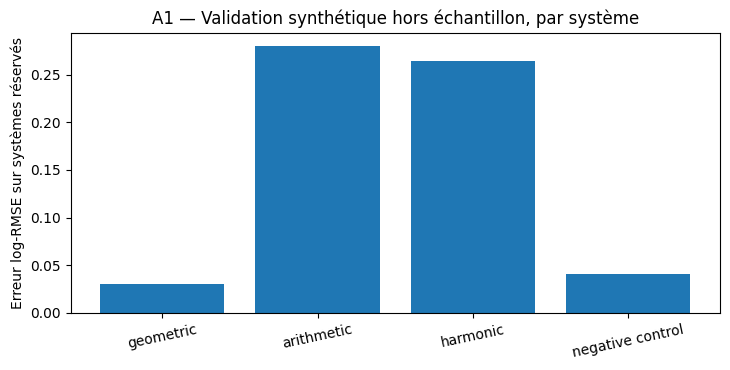

In [10]:
# The test fold is opened only after model selection was fixed above.
test_scores={fam:log_rmse(family_model(fam,fits[fam],X[idx_test]),Y_obs[idx_test]) for fam in families}
selected_test=test_scores[selected]
# Negative control: destroy pairing between training systems and their observations.
shuffled=Y_obs[train_complete][rng.permutation(len(train_complete))]
alpha_null=train_model('geometric',train_complete,shuffled)
null_test=log_rmse(family_model('geometric',alpha_null,X[idx_test]),Y_obs[idx_test])
check('test_selected_outperforms_arithmetic',selected_test<test_scores['arithmetic'])
check('test_selected_outperforms_harmonic',selected_test<test_scores['harmonic'])
check('negative_shuffled_worse_on_test',null_test>selected_test)
check('test_noise_scale_reasonable',selected_test<.07)
check('test_not_zero_due_noise',selected_test>1e-5)
check('shuffled_training_has_large_in_sample_mismatch',log_rmse(family_model('geometric',alpha_null,X[train_complete]),shuffled)>4*log_rmse(family_model('geometric',fits['geometric'],X[train_complete]),Y_obs[train_complete]))
print('HELDOUT test log-RMSE',test_scores,'; permuted-training geometric test score=',null_test)
fig, ax=plt.subplots(figsize=(7.4,3.8))
labels=['geometric','arithmetic','harmonic','negative control']
vals=[test_scores[f] for f in families]+[null_test]
ax.bar(labels, vals)
ax.set_ylabel('Erreur log-RMSE sur systèmes réservés')
ax.set_title('A1 — Validation synthétique hors échantillon, par système')
ax.tick_params(axis='x', labelrotation=12)
fig.tight_layout()
plt.show()


## NIVEAU 4 — Verdict et conditions de passage

**Résultats établis dans la portée du notebook** : pour des observables synthétiques positives et des opérateurs fixés a priori, les trois familles additive, multiplicative et inverse sont inversibles sous condition de rang ; une matrice déficiente crée des familles de solutions indiscernables. L'interaction à coefficient inconnu nécessite davantage de mesures indépendantes, et le mauvais conditionnement amplifie le bruit. La sélection d'un modèle générateur sur données synthétiques hors échantillon n'est **pas une découverte sur données astronomiques réelles**.

**Résultats non établis** : existence d'un opérateur CHH naturel commun à tous les systèmes physiques, possibilité générale de retrouver un sous-cube arbitraire, constante universelle \(\sqrt{22}\), équations d'évolution CHH, nouvelle interaction gravitationnelle GVH et progrès empirique sur les données ALMA.

**Décision** : audit méthodologique A1 = `PASS_METHOD_SYNTHETIC`; science physique = `OPEN_LOCK`. Le protocole pré-gel ne devient pas figé par ce résultat.

**Suite autorisée** : A2 / `GVH_CHH_INVERSE_03B_Real_Catalog_SelectionBias_and_Calibration_Gate_FAST` (à construire avec jeu réel documenté, protocoles de sélection de catalogue, incertitudes et baseline indépendante) ; en parallèle B1/CHH-14, C1/ROOT22 santé, D1/ALMA préenregistré. Les observations ALMA restent `GVH_USED=False`.


In [11]:
RESULTS={
 'notebook':NAME,
 'status':'PASS_METHOD_SYNTHETIC_OPEN_PHYSICAL_LOCK',
 'governance':'EXPLORATORY_PRE_FREEZE_NOT_APPROVED',
 'protocol_baseline':'GVH_CHH_PROTOCOL_FROZEN_v1.0',
 'levels':{'1_GVH_CHH':'COMPOSITION_ONLY_NO_INTRINSIC_GLOBAL_DERIVATIVE',
           '2_KNOWN_PHYSICS':'OPERATOR_FAMILIES_NOT_ASSERTED_AS_UNIVERSAL_LAWS',
           '3_NUMERICAL':'SYNTHETIC_RANK_NOISE_MISSING_SYSTEM_HELDOUT',
           '4_VERDICT':'METHODOLOGY_PASS_NO_NEW_PHYSICAL_LAW'},
 'source_hashes_sha256':SOURCE_HASHES,
 'reproducibility':{'seed':SEED,'numpy':np.__version__,'scipy':scipy.__version__,'sympy':sp.__version__},
 'dimensional_conventions':{'x_i':'[M] arbitrary positive mass-like unit', 'Y_j':'[M] same unit','W_gamma_h':'dimensionless','normalized_weights':True},
 'model_families':{
  'addition':{'full_rank':rank(W),'deficient_rank':rank(W_bad),'exact_reconstruction':x_back.tolist()},
  'multiplication':{'full_rank':rank(J_geo),'deficient_rank':1,'exact_reconstruction':x_geo.tolist()},
  'inverse':{'full_rank':rank(J_h),'deficient_rank':1,'exact_reconstruction':x_h.tolist()},
  'interaction':{'three_obs_rank':rank(J3),'four_obs_rank':rank(J4), 'full_reconstruction':fit4.x.tolist(), 'true_gamma':gamma_true}
 },
 'noise':{'well_conditioned':cond_w,'ill_conditioned':cond_ill,'rmse_well':rmse_good,'rmse_ill':rmse_bad,'monte_carlo_samples':nmc},
 'cross_system_synthetic':{'n_systems':N,'n_train':len(train_complete),'n_train_missing':len(train_missing),'n_validation':len(idx_valid),'n_test':len(idx_test), 'true_alpha':alpha_true, 'fit_alpha':fits,'validation_log_rmse':val_scores,'selection':selected,'heldout_test_log_rmse':test_scores,'shuffled_control_test_log_rmse':null_test},
 'root22':{'algebraic_root':'sqrt(22)','coefficient':'(sqrt(22)-4)/9','universal_constant_validated':False,'free_scale_absorbs_root':True},
 'physical_validation':False, 'real_observational_inputs':False, 'ALMA_GVH_USED':False,
 'next':'GVH_CHH_INVERSE_03B_Real_Catalog_SelectionBias_and_Calibration_Gate_FAST',
 'checks':CHECKS,
 'checks_total':len(CHECKS), 'checks_passed':sum(a['pass'] for a in CHECKS)
}
assert RESULTS['checks_total']==RESULTS['checks_passed']
path=ROOT/(NAME+'_results.json')
path.write_text(json.dumps(RESULTS,ensure_ascii=False,indent=2,sort_keys=True)+'\n',encoding='utf-8')
print('RESULTS',path,'; check count',RESULTS['checks_total'],';',RESULTS['status'])
print('CAUTION: this validates only synthetic numerical/mathematical methodology, not a physical law.')


RESULTS /mnt/data/GVH_CHH_Conditional_Composition_and_Coefficient_Identifiability_Gate_FAST_results.json ; check count 65 ; PASS_METHOD_SYNTHETIC_OPEN_PHYSICAL_LOCK
CAUTION: this validates only synthetic numerical/mathematical methodology, not a physical law.
